**PIPELINE 1**

In [1]:
# ===== TAHAP 1: BUSINESS UNDERSTANDING =====
PROBLEM = """
Tujuan   : Membangun model klasifikasi citra MRI otak untuk memprediksi jenis tumor.
Input    : 1 gambar MRI otak
Output   : kelas tumor + probabilitas tiap kelas
Metrik   : Accuracy, Precision, Recall, F1 (macro), Confusion Matrix
Catatan  : Proyek edukasi, BUKAN alat diagnosis medis.
"""
print(PROBLEM)


Tujuan   : Membangun model klasifikasi citra MRI otak untuk memprediksi jenis tumor.
Input    : 1 gambar MRI otak
Output   : kelas tumor + probabilitas tiap kelas
Metrik   : Accuracy, Precision, Recall, F1 (macro), Confusion Matrix
Catatan  : Proyek edukasi, BUKAN alat diagnosis medis.



In [2]:
# ===== TAHAP 2: DATA COLLECTION =====
!pip install -q kagglehub

import kagglehub, os
from pathlib import Path

DATA_DIR = kagglehub.dataset_download("denizkavi1/brain-tumor")
print("Dataset ada di:", DATA_DIR)

# Lihat struktur folder (3 level) beserta jumlah file per folder
IMG_EXT = {".png", ".jpg", ".jpeg", ".bmp", ".tif", ".tiff"}
for root, dirs, files in os.walk(DATA_DIR):
    depth = Path(root).relative_to(DATA_DIR).parts
    if len(depth) <= 3:
        n_img = sum(Path(f).suffix.lower() in IMG_EXT for f in files)
        other = {Path(f).suffix.lower() for f in files} - IMG_EXT
        print("  " * len(depth) + f"{Path(root).name}/  gambar={n_img}  lain={other or ''}")

100%|██████████| 700M/700M [00:06<00:00, 114MB/s]

Extracting files...


Dataset ada di: /root/.cache/kagglehub/datasets/denizkavi1/brain-tumor/versions/2
2/  gambar=0  lain=
  1/  gambar=708  lain=
  2/  gambar=1426  lain=
  3/  gambar=930  lain=


In [3]:
# Buat tabel (DataFrame) berisi path gambar dan label dari nama folder induk
import pandas as pd

rows = []
for p in Path(DATA_DIR).rglob("*"):
    if p.suffix.lower() in IMG_EXT:
        rel = str(p.relative_to(DATA_DIR)).lower()
        if "mask" in rel:          # lewati file mask segmentasi
            continue
        rows.append({"path": str(p), "label": p.parent.name})

df = pd.DataFrame(rows)
print("Total gambar:", len(df))
print(df["label"].value_counts())
df.head()

Total gambar: 3064
label
2    1426
3     930
1     708
Name: count, dtype: int64


,path,label
0,/root/.cache/kagglehub/datasets/denizkavi1/bra...,1
1,/root/.cache/kagglehub/datasets/denizkavi1/bra...,1
2,/root/.cache/kagglehub/datasets/denizkavi1/bra...,1
3,/root/.cache/kagglehub/datasets/denizkavi1/bra...,1
4,/root/.cache/kagglehub/datasets/denizkavi1/bra...,1


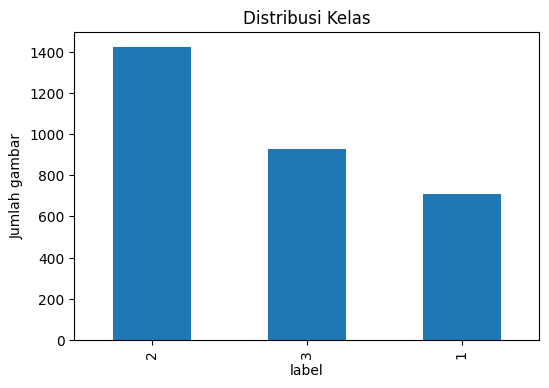

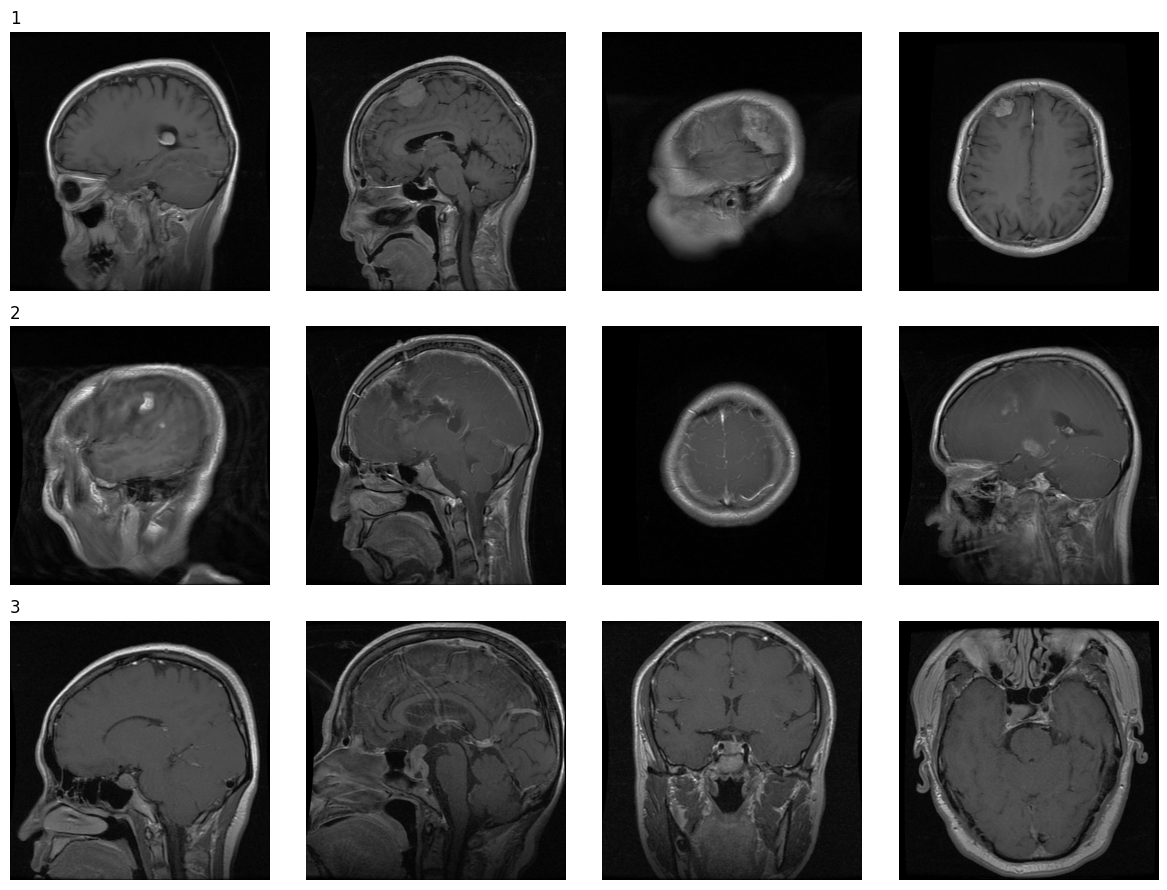

Ukuran gambar paling sering: {(512, 512): 299, (256, 256): 1}
Mode warna: {'RGBA': 300}
Gambar duplikat: 0


In [4]:
# ===== TAHAP 3: EDA =====
import matplotlib.pyplot as plt
import numpy as np
from PIL import Image
import hashlib

# 3.1 Distribusi kelas
ax = df["label"].value_counts().plot(kind="bar", figsize=(6, 4), title="Distribusi Kelas")
ax.set_ylabel("Jumlah gambar"); plt.show()

# 3.2 Contoh gambar per kelas
classes = sorted(df["label"].unique())
fig, axes = plt.subplots(len(classes), 4, figsize=(12, 3 * len(classes)))
axes = np.atleast_2d(axes)
for i, c in enumerate(classes):
    for j, p in enumerate(df[df.label == c].sample(4, random_state=1)["path"]):
        axes[i, j].imshow(Image.open(p).convert("L"), cmap="gray")
        axes[i, j].axis("off")
        if j == 0: axes[i, j].set_title(c, loc="left")
plt.tight_layout(); plt.show()

# 3.3 Ukuran dan mode gambar
sample = df.sample(min(300, len(df)), random_state=1)
info = [(Image.open(p).size, Image.open(p).mode) for p in sample["path"]]
print("Ukuran gambar paling sering:", pd.Series([s for s, _ in info]).value_counts().head(5).to_dict())
print("Mode warna:", pd.Series([m for _, m in info]).value_counts().to_dict())

# 3.4 Cek duplikat (penting agar tidak terjadi kebocoran data)
def md5(p):
    with open(p, "rb") as f:
        return hashlib.md5(f.read()).hexdigest()

df["hash"] = df["path"].apply(md5)
n_dup = df.duplicated("hash").sum()
print(f"Gambar duplikat: {n_dup}")

In [5]:
# ===== TAHAP 4: DATA PREPARATION =====
import torch
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from sklearn.model_selection import train_test_split

SEED = 42
torch.manual_seed(SEED); np.random.seed(SEED)

# 4.1 Hapus duplikat
df = df.drop_duplicates("hash").reset_index(drop=True)

# 4.2 Encode label
classes = sorted(df["label"].unique())
class_to_idx = {c: i for i, c in enumerate(classes)}
df["y"] = df["label"].map(class_to_idx)
print("Kelas:", class_to_idx)

# 4.3 Split stratified: 70% train, 15% val, 15% test
train_df, temp_df = train_test_split(df, test_size=0.30, stratify=df["y"], random_state=SEED)
val_df, test_df = train_test_split(temp_df, test_size=0.50, stratify=temp_df["y"], random_state=SEED)
print(len(train_df), len(val_df), len(test_df))

# 4.4 Transformasi (augmentasi hanya untuk train)
IMG_SIZE = 224
MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]

train_tf = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10),
    transforms.ColorJitter(brightness=0.15, contrast=0.15),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])
eval_tf = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])

class MRIDataset(Dataset):
    def __init__(self, frame, tf):
        self.paths = frame["path"].tolist()
        self.ys = frame["y"].tolist()
        self.tf = tf
    def __len__(self): return len(self.paths)
    def __getitem__(self, i):
        img = Image.open(self.paths[i]).convert("RGB")   # grayscale -> 3 channel
        return self.tf(img), self.ys[i]

BATCH = 32
train_dl = DataLoader(MRIDataset(train_df, train_tf), batch_size=BATCH, shuffle=True, num_workers=2)
val_dl   = DataLoader(MRIDataset(val_df, eval_tf),   batch_size=BATCH, num_workers=2)
test_dl  = DataLoader(MRIDataset(test_df, eval_tf),  batch_size=BATCH, num_workers=2)

# 4.5 Bobot kelas untuk menangani ketidakseimbangan data
counts = train_df["y"].value_counts().sort_index().values
class_weights = torch.tensor(counts.sum() / (len(counts) * counts), dtype=torch.float)
print("Bobot kelas:", class_weights)

Kelas: {'1': 0, '2': 1, '3': 2}
2144 460 460
Bobot kelas: tensor([1.4438, 0.7161, 1.0978])


Device: cuda
Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 102MB/s]


Epoch 01 | train loss 0.355 acc 0.857 | val loss 0.867 acc 0.696
Epoch 02 | train loss 0.169 acc 0.947 | val loss 0.147 acc 0.950
Epoch 03 | train loss 0.119 acc 0.958 | val loss 0.603 acc 0.815
Epoch 04 | train loss 0.074 acc 0.972 | val loss 0.119 acc 0.970
Epoch 05 | train loss 0.065 acc 0.979 | val loss 0.061 acc 0.980
Epoch 06 | train loss 0.044 acc 0.986 | val loss 0.081 acc 0.978
Epoch 07 | train loss 0.035 acc 0.988 | val loss 0.107 acc 0.948
Epoch 08 | train loss 0.027 acc 0.992 | val loss 0.041 acc 0.989
Epoch 09 | train loss 0.011 acc 0.997 | val loss 0.024 acc 0.989
Epoch 10 | train loss 0.004 acc 1.000 | val loss 0.032 acc 0.987
Epoch 11 | train loss 0.008 acc 0.998 | val loss 0.040 acc 0.991
Epoch 12 | train loss 0.004 acc 0.999 | val loss 0.032 acc 0.987
Epoch 13 | train loss 0.005 acc 1.000 | val loss 0.030 acc 0.987
Epoch 14 | train loss 0.003 acc 1.000 | val loss 0.031 acc 0.987
Epoch 15 | train loss 0.002 acc 1.000 | val loss 0.031 acc 0.983
Early stopping.


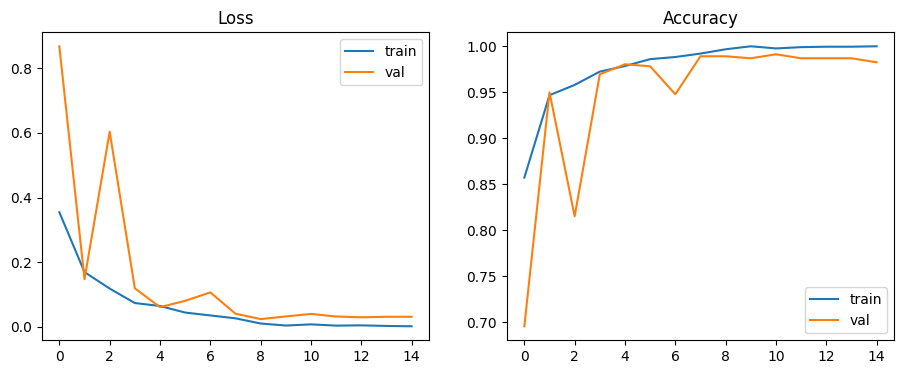

In [6]:
# ===== TAHAP 5: MODELING =====
import torch.nn as nn
from torchvision import models
from tqdm.auto import tqdm

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", device)

model = models.resnet18(weights="IMAGENET1K_V1")
model.fc = nn.Sequential(nn.Dropout(0.3), nn.Linear(model.fc.in_features, len(classes)))
model.to(device)

loss_fn = nn.CrossEntropyLoss(weight=class_weights.to(device))
opt = torch.optim.AdamW(model.parameters(), lr=3e-4, weight_decay=1e-4)
EPOCHS = 15
sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=EPOCHS)
scaler = torch.amp.GradScaler("cuda", enabled=(device == "cuda"))

def run_epoch(dl, train=True):
    model.train(train)
    total_loss, correct, n = 0, 0, 0
    with torch.set_grad_enabled(train):
        for x, y in dl:
            x, y = x.to(device), y.to(device)
            with torch.autocast(device_type="cuda", enabled=(device == "cuda")):
                out = model(x)
                loss = loss_fn(out, y)
            if train:
                opt.zero_grad()
                scaler.scale(loss).backward()
                scaler.step(opt); scaler.update()
            total_loss += loss.item() * len(y)
            correct += (out.argmax(1) == y).sum().item()
            n += len(y)
    return total_loss / n, correct / n

history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}
best_val, patience, wait = 0, 4, 0

for ep in range(EPOCHS):
    tl, ta = run_epoch(train_dl, True)
    vl, va = run_epoch(val_dl, False)
    sched.step()
    for k, v in zip(history, [tl, vl, ta, va]): history[k].append(v)
    print(f"Epoch {ep+1:02d} | train loss {tl:.3f} acc {ta:.3f} | val loss {vl:.3f} acc {va:.3f}")

    if va > best_val:                      # simpan model terbaik
        best_val, wait = va, 0
        torch.save(model.state_dict(), "best_model.pth")
    else:                                 # early stopping
        wait += 1
        if wait >= patience:
            print("Early stopping."); break

# Kurva pembelajaran
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(history["train_loss"], label="train"); ax[0].plot(history["val_loss"], label="val"); ax[0].set_title("Loss"); ax[0].legend()
ax[1].plot(history["train_acc"], label="train"); ax[1].plot(history["val_acc"], label="val"); ax[1].set_title("Accuracy"); ax[1].legend()
plt.show()

              precision    recall  f1-score   support

           1      0.962     0.944     0.953       107
           2      0.977     0.981     0.979       214
           3      0.979     0.986     0.982       139

    accuracy                          0.974       460
   macro avg      0.972     0.970     0.971       460
weighted avg      0.974     0.974     0.974       460



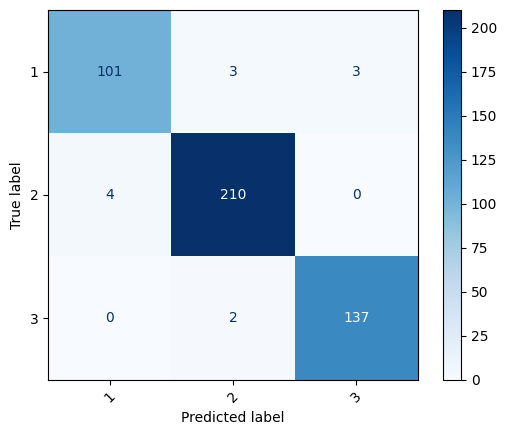

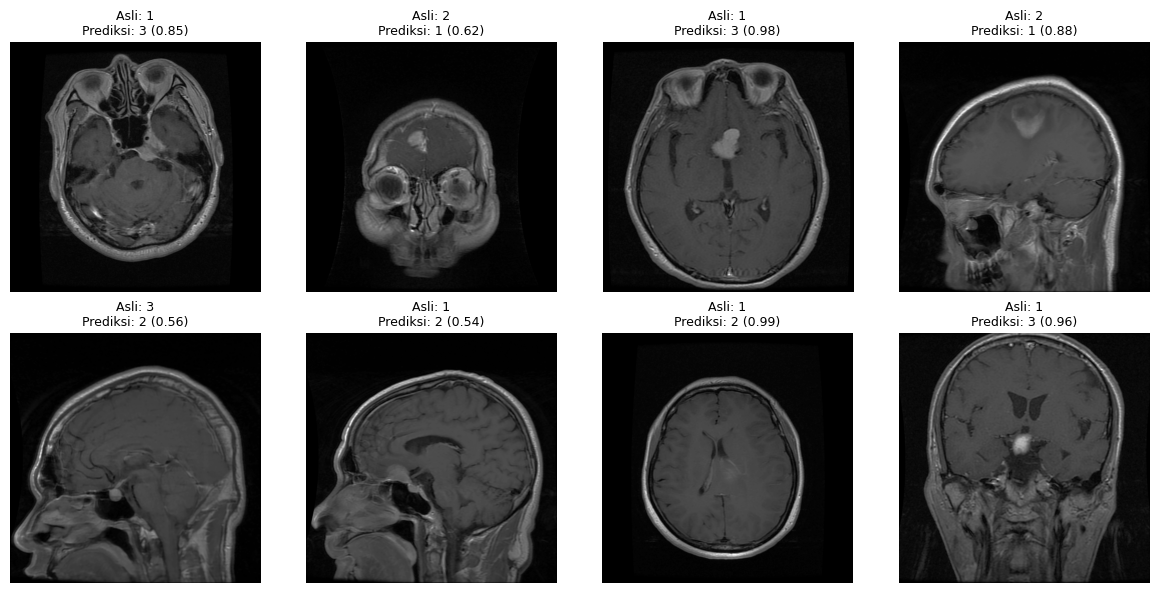

In [7]:
# ===== TAHAP 6: EVALUATION (pada data uji) =====
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

model.load_state_dict(torch.load("best_model.pth", map_location=device))
model.eval()

y_true, y_pred, y_prob = [], [], []
with torch.no_grad():
    for x, y in test_dl:
        p = torch.softmax(model(x.to(device)), dim=1).cpu()
        y_prob.append(p); y_pred += p.argmax(1).tolist(); y_true += y.tolist()
y_prob = torch.cat(y_prob).numpy()

print(classification_report(y_true, y_pred, target_names=classes, digits=3))

cm = confusion_matrix(y_true, y_pred)
ConfusionMatrixDisplay(cm, display_labels=classes).plot(cmap="Blues", xticks_rotation=45)
plt.show()

# Analisis kesalahan: tampilkan prediksi yang salah
wrong = [i for i, (t, p) in enumerate(zip(y_true, y_pred)) if t != p][:8]
if wrong:
    fig, axes = plt.subplots(2, 4, figsize=(12, 6))
    for ax, i in zip(axes.ravel(), wrong):
        ax.imshow(Image.open(test_df.iloc[i]["path"]).convert("L"), cmap="gray")
        ax.set_title(f"Asli: {classes[y_true[i]]}\nPrediksi: {classes[y_pred[i]]} ({y_prob[i].max():.2f})", fontsize=9)
        ax.axis("off")
    plt.tight_layout(); plt.show()

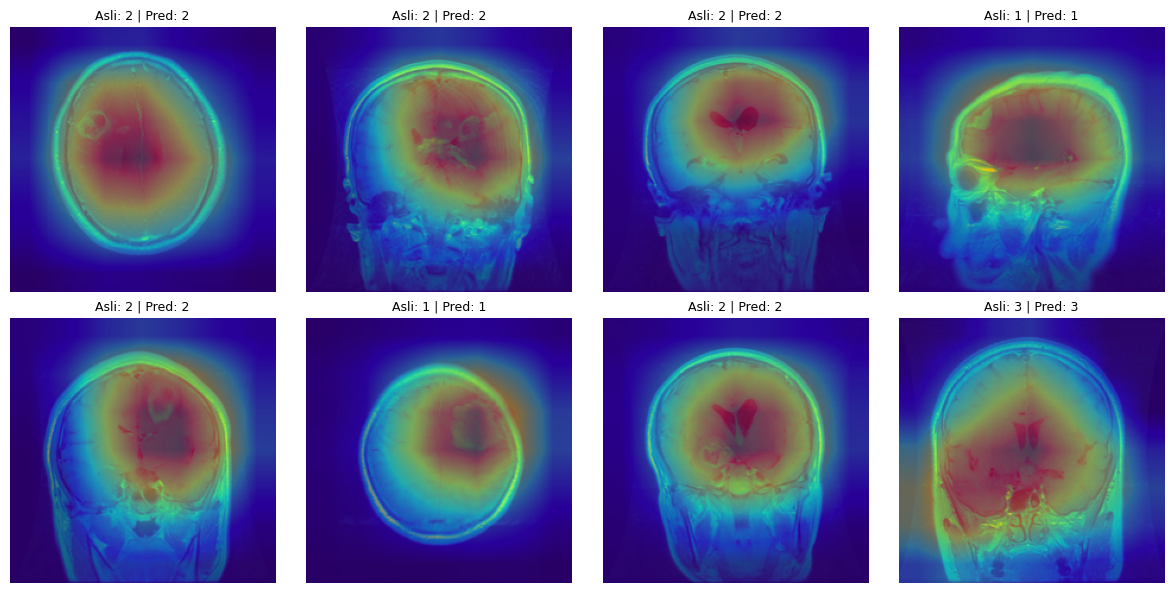

In [8]:
# Explainability: Grad-CAM (area yang diperhatikan model)
import torch.nn.functional as F

def grad_cam(img_path):
    img = Image.open(img_path).convert("RGB")
    x = eval_tf(img).unsqueeze(0).to(device)
    feats, grads = [], []
    layer = model.layer4[-1]
    h1 = layer.register_forward_hook(lambda m, i, o: feats.append(o))
    h2 = layer.register_full_backward_hook(lambda m, gi, go: grads.append(go[0]))
    out = model(x)
    cls = out.argmax(1).item()
    model.zero_grad(); out[0, cls].backward()
    h1.remove(); h2.remove()
    w = grads[0].mean(dim=(2, 3), keepdim=True)
    cam = F.relu((w * feats[0]).sum(1, keepdim=True))
    cam = F.interpolate(cam, size=(IMG_SIZE, IMG_SIZE), mode="bilinear")[0, 0]
    cam = (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)
    return img.resize((IMG_SIZE, IMG_SIZE)), cam.detach().cpu().numpy(), classes[cls]

fig, axes = plt.subplots(2, 4, figsize=(12, 6))
for ax, (_, r) in zip(axes.ravel(), test_df.sample(8, random_state=3).iterrows()):
    img, cam, pred = grad_cam(r["path"])
    ax.imshow(img); ax.imshow(cam, cmap="jet", alpha=0.4)
    ax.set_title(f"Asli: {r['label']} | Pred: {pred}", fontsize=9); ax.axis("off")
plt.tight_layout(); plt.show()

In [9]:
# ===== TAHAP 7: SIMPAN ARTEFAK MODEL =====
import json
from google.colab import drive, files

meta = {
    "architecture": "resnet18",
    "classes": classes,
    "img_size": IMG_SIZE,
    "mean": MEAN, "std": STD,
    "test_accuracy": float(np.mean(np.array(y_true) == np.array(y_pred))),
    "dropout_head": True,
}
json.dump(meta, open("model_meta.json", "w"), indent=2)

# Simpan ke Google Drive agar tidak hilang
drive.mount("/content/drive")
os.makedirs("/content/drive/MyDrive/brain_tumor_model", exist_ok=True)
!cp best_model.pth model_meta.json /content/drive/MyDrive/brain_tumor_model/

# (Opsional) unduh ke komputer
# files.download("best_model.pth"); files.download("model_meta.json")

Mounted at /content/drive


**PIPELINE 2**

In [17]:
# ===== TAHAP 1: SETUP & LOAD MODEL =====
!pip install -q gradio

import json, os
import numpy as np
import torch, torch.nn as nn, torch.nn.functional as F
from PIL import Image, ImageOps
from torchvision import models, transforms
import matplotlib.cm as cm
from google.colab import drive

drive.mount("/content/drive")
ART = "/content/drive/MyDrive/brain_tumor_model"

meta = json.load(open(f"{ART}/model_meta.json"))
CLASSES  = meta["classes"]
NAMA_TAMPIL = {"1": "Meningioma", "2": "Glioma", "3": "Pituitary"}  # sesuaikan dengan dokumentasi
CLASSES_DISPLAY = [NAMA_TAMPIL.get(c, c) for c in CLASSES]
print(CLASSES_DISPLAY)
IMG_SIZE = meta["img_size"]
MEAN, STD = meta["mean"], meta["std"]
print("Kelas:", CLASSES, "| Akurasi uji Pipeline 1:", round(meta["test_accuracy"], 3))

device = "cuda" if torch.cuda.is_available() else "cpu"

# Arsitektur HARUS sama persis dengan saat training
model = models.resnet18()
model.fc = nn.Sequential(nn.Dropout(0.3), nn.Linear(model.fc.in_features, len(CLASSES)))
model.load_state_dict(torch.load(f"{ART}/best_model.pth", map_location=device))
model.to(device).eval()
print("Model berhasil dimuat di", device)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
['Meningioma', 'Glioma', 'Pituitary']
Kelas: ['1', '2', '3'] | Akurasi uji Pipeline 1: 0.974
Model berhasil dimuat di cuda


In [18]:
# ===== TAHAP 2: PREPROCESSING & VALIDASI =====
# PENTING: preprocessing inferensi harus SAMA dengan eval_tf di Pipeline 1
# (Resize -> ToTensor -> Normalize). Jangan tambah autocontrast, karena model
# tidak dilatih dengan itu dan hasilnya bisa bergeser.
eval_tf = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])

def standardize(img: Image.Image) -> Image.Image:
    img = ImageOps.exif_transpose(img)   # perbaiki rotasi dari HP/kamera
    return img.convert("RGB")            # grayscale/RGBA -> RGB

def looks_grayscale(img: Image.Image, tol=12) -> bool:
    a = np.asarray(img).astype(int)
    return (np.abs(a[..., 0] - a[..., 1]).mean() < tol and
            np.abs(a[..., 1] - a[..., 2]).mean() < tol)

def validate_image(img: Image.Image):
    """Kembalikan (lolos, pesan). Tahap penyaring sebelum model dipakai."""
    w, h = img.size
    if min(w, h) < 64:
        return False, "Gambar terlalu kecil (minimal 64 piksel)."
    if not looks_grayscale(img):
        return False, "Gambar berwarna terdeteksi. MRI otak umumnya grayscale, jadi gambar ini kemungkinan bukan MRI."
    return True, "OK"

In [19]:
# ===== TAHAP 3: INFERENSI + GRAD-CAM + PENGAMAN =====
def predict_with_cam(img: Image.Image):
    """Satu kali forward pass menghasilkan probabilitas sekaligus peta Grad-CAM."""
    store = {}
    def fwd_hook(m, i, o):
        store["feat"] = o
        o.register_hook(lambda g: store.__setitem__("grad", g))
    h = model.layer4[-1].register_forward_hook(fwd_hook)

    x = eval_tf(img).unsqueeze(0).to(device)
    model.zero_grad()
    out = model(x)
    probs = torch.softmax(out, dim=1)[0]
    cls = int(probs.argmax())
    out[0, cls].backward()
    h.remove()

    w = store["grad"].mean(dim=(2, 3), keepdim=True)
    cam = F.relu((w * store["feat"]).sum(1, keepdim=True))
    cam = F.interpolate(cam, size=(IMG_SIZE, IMG_SIZE), mode="bilinear")[0, 0]
    cam = ((cam - cam.min()) / (cam.max() - cam.min() + 1e-8)).detach().cpu().numpy()
    return probs.detach().cpu().numpy(), cam

def overlay(img: Image.Image, cam, alpha=0.4):
    heat = (cm.jet(cam)[..., :3] * 255).astype(np.uint8)
    base = np.asarray(img.resize((IMG_SIZE, IMG_SIZE))).astype(float)
    return Image.fromarray(((1 - alpha) * base + alpha * heat).astype(np.uint8))

def normalized_entropy(p):
    """0 = model sangat yakin, 1 = sama sekali tidak yakin."""
    p = np.clip(p, 1e-8, 1)
    return float(-(p * np.log(p)).sum() / np.log(len(p)))

def analyze(img: Image.Image, conf_threshold=0.80):
    """Fungsi inti sistem. Mengembalikan dict hasil lengkap."""
    img = standardize(img)

    ok, msg = validate_image(img)
    if not ok:
        return {"status": "ditolak", "message": msg}

    probs, cam = predict_with_cam(img)
    top = int(probs.argmax())
    conf = float(probs[top])
    ent = normalized_entropy(probs)

    if conf < conf_threshold or ent > 0.6:
        status = "tidak_yakin"
        message = (f"Model tidak yakin (confidence {conf:.0%}). Pastikan gambar adalah "
                   "MRI otak yang jelas, atau konsultasikan dengan tenaga medis.")
    else:
        status = "ok"
        # message = f"Prediksi: **{CLASSES[top]}** (confidence {conf:.0%})"
        message = f"Prediksi: **{CLASSES_DISPLAY[top]}** (confidence {conf:.0%})"

    return {
        "status": status, "message": message,
        # "probs": {CLASSES[i]: float(probs[i]) for i in range(len(CLASSES))},
        "probs": {CLASSES_DISPLAY[i]: float(probs[i]) for i in range(len(CLASSES))},
        "cam_image": overlay(img, cam),
    }

In [20]:
# ===== TAHAP 4: ANTARMUKA =====
import gradio as gr

DISCLAIMER = ("⚠️ **Disclaimer:** Sistem ini adalah proyek edukasi/percobaan dan **bukan alat diagnosis medis**. "
              "Hasil tidak boleh dipakai untuk keputusan klinis. Konsultasikan dengan dokter.")

def ui_predict(image, threshold):
    if image is None:
        return {}, "Silakan upload gambar terlebih dahulu.", None
    r = analyze(image, conf_threshold=threshold)
    if r["status"] == "ditolak":
        return {}, f"❌ {r['message']}", None
    prefix = "✅ " if r["status"] == "ok" else "⚠️ "
    return r["probs"], prefix + r["message"], r["cam_image"]

with gr.Blocks(title="Klasifikasi Tumor Otak (Demo Edukasi)") as demo:
    gr.Markdown("# 🧠 Klasifikasi Citra MRI Tumor Otak")
    gr.Markdown(DISCLAIMER)
    with gr.Row():
        with gr.Column():
            inp = gr.Image(type="pil", label="Upload MRI otak (PNG/JPG)")
            thr = gr.Slider(0.5, 0.99, value=0.80, step=0.01, label="Ambang confidence minimum")
            btn = gr.Button("Prediksi", variant="primary")
        with gr.Column():
            msg = gr.Markdown()
            lbl = gr.Label(num_top_classes=len(CLASSES), label="Probabilitas tiap kelas")
            cam = gr.Image(label="Grad-CAM (area yang diperhatikan model)")
    btn.click(ui_predict, [inp, thr], [lbl, msg, cam])

demo.launch(share=True, debug=False)   # share=True membuat link publik sementara

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://5e9789fe56f9ee60ba.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [21]:
# ===== TAHAP 5: PENGUJIAN =====
import glob, random

# 5.1 Gambar dari dataset (pakai path dari DataFrame Pipeline 1 jika masih ada di sesi)
# Jika sesi baru, ganti dengan path manual gambar uji Anda.
try:
    contoh = test_df.sample(5, random_state=7)
    for _, r in contoh.iterrows():
        res = analyze(Image.open(r["path"]))
        top = max(res["probs"], key=res["probs"].get) if "probs" in res else "-"
        print(f"Asli: {r['label']:<12} | Sistem: {res['status']:<12} | Prediksi: {top}")
except NameError:
    print("test_df tidak ada di sesi ini, uji manual lewat antarmuka.")

# 5.2 Uji gambar non-MRI: harus DITOLAK atau "tidak yakin"
noise = Image.fromarray((np.random.rand(256, 256, 3) * 255).astype(np.uint8))   # gambar acak berwarna
print("Gambar acak berwarna ->", analyze(noise)["status"])

gradient = Image.fromarray(np.tile(np.linspace(0, 255, 256), (256, 1)).astype(np.uint8))  # gradien grayscale
print("Gradien grayscale   ->", analyze(gradient)["status"])

Asli: 2            | Sistem: ditolak      | Prediksi: -
Asli: 1            | Sistem: ditolak      | Prediksi: -
Asli: 1            | Sistem: ditolak      | Prediksi: -
Asli: 2            | Sistem: ditolak      | Prediksi: -
Asli: 3            | Sistem: ditolak      | Prediksi: -
Gambar acak berwarna -> ditolak
Gradien grayscale   -> tidak_yakin
